# 10 — Does the data contain types, or one continuum?

Notebook 09 found that the item's identity carries a large, durable share of the error,
and that the ranking of items by difficulty still correlates with itself six months
later. **A static grouping has something real to hold on to.** Had difficulty turned out
to be a property of the window instead, there would be nothing here to group and the
question would have closed on a ceiling.

It is not, which makes this notebook the deciding question. If the
population contains **discrete types**, a grouping is a real instrument: fine-tune per
type, cross-learn inside a type, one model per type. If it is **one continuum**, then
the stable differences between items are a matter of degree, a cut through them is
arbitrary wherever it is placed, and the right response is a continuous covariate — one
Chronos-2 reads off the history by itself — rather than a partition.

**The object.** Not the level of a series, which would sort items by how much they sell,
but its **shape**: the share of a week falling on each day. M5 is daily, so the natural
period is the week and the profile has 7 dimensions, one per weekday. For a series
observed over weeks $w = 1 \dots W$:

$$\alpha_{w,d} = \frac{y_{w,d}}{\sum_{d} y_{w,d}}, \qquad
  v_d = \frac{\sum_{w} \alpha_{w,d}}{\sum_{d}\sum_{w} \alpha_{w,d}}$$

Every week gets an equal say regardless of its volume, which is the point of looking at
shape. The second normalisation is a division by $W$, so $v$ sums to 1 by construction.

**Why an audit and not just a clustering.** Any clustering algorithm returns clusters.
Four questions decide whether those clusters mean anything, and each can kill the next:
is the object stable enough to cluster (step 0); could the pipeline find structure if
there were any (step 1); does it invent structure when there is none (step 2); is the
distance measuring shape or merely where the week sits (step 4). Steps 3, 5 and 6 of the
full audit — the dimension sweep, the drift decomposition and the forward-scored window
length — are out of scope here and named again at the end.

**Decision rule, fixed before looking.** Discrete types are claimed only if *all* of:
prediction strength clears 0.80 at some $K \geq 2$; that $K$ beats the fitted-continuum
null at $p < 0.05$; and the separation achieved exceeds the detection floor measured in
step 1. Any one failing means continuum, or an underpowered test — and step 1 is what
tells those two apart.

Validation window only: like every choice in this study, nothing here reads the test window.

In [1]:
%load_ext autoreload
%autoreload 2

import json

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

from m5_chronos2.data import ARTIFACTS_DIR, roster_name
from m5_chronos2.evaluation import make_windows
from m5_chronos2.shapes import (
    ARI_THRESHOLD, PREDICTION_STRENGTH_THRESHOLD, WEEKDAYS,
    counting_noise_ratio, fitted_null, geometry_comparison, icc1, k_hat,
    null_envelope, positive_control, separation, shape_matrix, shift_test,
    split_half_reliability, umap_layout, weekly_shapes, weekly_share_array, _fit_gmm,
)
from m5_chronos2.plots import (
    GRID_COLOR, MAIN_COLOR, MUTED_TEXT_COLOR, TEXT_COLOR, use_blog_style,
)

use_blog_style()
DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

## Settings

In [2]:
SAMPLE_SIZE = 500
SEED = 42
NAME = roster_name(SAMPLE_SIZE, SEED)

MIN_WEEKS = 26           # at least half a year of complete weeks per series
MAX_K = 6                # cluster counts to test
N_DRAWS = 10             # splits per prediction-strength estimate
N_NULLS = 40             # fitted continua; the p-value cannot go below 1/(N+1) = 0.024
SEP_GRID = [0.0, 0.15, 0.25, 0.4, 0.6, 0.9]

# The null envelope is the one slow step: 41 clusterings of the whole population, a few
# minutes on a laptop. It is cached so re-running the notebook to adjust a figure costs
# nothing. Set this to True after changing anything the envelope depends on.
FORCE_RECOMPUTE = False

# Figures and the video use a 2-D layout; no decision does. Everything below is
# decided in the full 7 dimensions.
LAYOUT_SEED = 0

In [3]:
sales = pl.read_parquet(ARTIFACTS_DIR / f"sales_flags_{NAME}.parquet")
LAST_DAY = make_windows().filter(pl.col("role") == "validation")["origin"][0]

# What notebook 09 concluded, read rather than restated: the two notebooks must not
# drift apart if the sweep is ever re-run.
persistence_path = ARTIFACTS_DIR / f"error_persistence_{NAME}.json"
if persistence_path.exists():
    inherited = json.loads(persistence_path.read_text())
    print(f"From notebook 09: {inherited['verdict']}")
    print(f"  series share {100 * inherited['shares']['series_adjusted']:.1f}%, "
          f"consecutive-origin Spearman {inherited['spearman_consecutive_median']:+.2f}, "
          f"first vs last {inherited['spearman_first_vs_last']:+.2f}")
    volume = inherited.get("stable_vs_volume")
    if volume:
        print(f"  of that, {100 * volume['share_after_covariates']:.1f}% of the budget "
              f"survives removing volume and sparsity "
              f"(volume alone explains R2 = {volume['r2_of_alpha']:.2f} of alpha)")
else:
    inherited = None
    print("notebook 09 has not been run: its verdict is what makes this notebook's "
          "question the deciding one rather than a curiosity.")

From notebook 09: Partial persistence: weigh the gain against the complexity.
  series share 41.7%, consecutive-origin Spearman +0.52, first vs last +0.41
  of that, 15.6% of the budget survives removing volume and sparsity (volume alone explains R2 = 0.63 of alpha)


## 1. The object

One 7-dimensional profile per series, built on history up to the validation origin.

In [4]:
shapes_table = weekly_shapes(sales, last_day=LAST_DAY, min_weeks=MIN_WEEKS)
X = shape_matrix(shapes_table)

# The per-week shares, which step 0 needs: clustering consumes the pooled profile, but
# reliability can only be measured on the single weeks it was pooled from.
all_ids, all_blocks, all_totals = weekly_share_array(sales, last_day=LAST_DAY)
position = {series_id: index for index, series_id in enumerate(all_ids)}
rows = [position[series_id] for series_id in shapes_table["id"].to_list()]
blocks = [all_blocks[row] for row in rows]
totals = [all_totals[row] for row in rows]

assert len(blocks) == len(X)
assert np.allclose(X.sum(axis=1), 1.0), "a profile does not sum to 1"
print(f"{len(X)} series with at least {MIN_WEEKS} complete weeks "
      f"(of {sales['id'].n_unique()} in the roster)")
print(f"weeks per series: median {int(np.median(shapes_table['n_weeks']))}, "
      f"min {int(shapes_table['n_weeks'].min())}")

493 series with at least 26 complete weeks (of 500 in the roster)
weeks per series: median 158, min 26


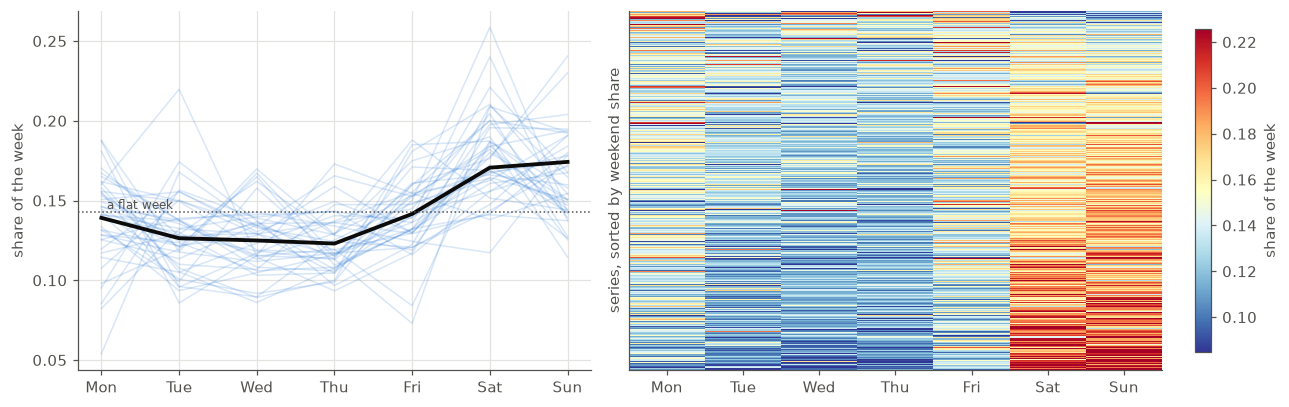

In [5]:
def plot_object(X, shapes_table):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8),
                             gridspec_kw={"width_ratios": [1, 1.3]})

    # Left: the population mean, and a handful of individual profiles over it.
    ax = axes[0]
    generator = np.random.default_rng(LAYOUT_SEED)
    for index in generator.choice(len(X), size=min(40, len(X)), replace=False):
        ax.plot(range(WEEKDAYS), X[index], color=MAIN_COLOR, alpha=0.18, linewidth=1)
    ax.plot(range(WEEKDAYS), X.mean(axis=0), color=TEXT_COLOR, linewidth=2.5)
    ax.axhline(1 / WEEKDAYS, color=MUTED_TEXT_COLOR, linestyle=":", linewidth=1)
    ax.text(0.02, 1 / WEEKDAYS, " a flat week", va="bottom", ha="left",
            color=MUTED_TEXT_COLOR, fontsize=8)
    ax.set_xticks(range(WEEKDAYS))
    ax.set_xticklabels(DAY_NAMES)
    ax.set_ylabel("share of the week")

    # Right: every profile, sorted by how much of the week falls at the weekend. A
    # population of types shows bands; a continuum shows a gradient.
    ax = axes[1]
    weekend = X[:, 5] + X[:, 6]
    image = ax.imshow(X[np.argsort(weekend)], aspect="auto", cmap="RdYlBu_r",
                      interpolation="nearest", vmin=np.quantile(X, 0.02),
                      vmax=np.quantile(X, 0.98))
    ax.set_xticks(range(WEEKDAYS))
    ax.set_xticklabels(DAY_NAMES)
    ax.set_yticks([])
    ax.set_ylabel("series, sorted by weekend share")
    ax.grid(False)
    fig.colorbar(image, ax=ax, label="share of the week", shrink=0.9)
    fig.tight_layout()
    return fig

plot_object(X, shapes_table)
plt.show()

## 2. Step 0 — is the object stable enough to cluster?

Normalising counts into shares makes a low-volume series pure noise: a week selling
three units can only produce a handful of distinct shape vectors. That is the single
most likely source of a spurious cluster, so it is measured before anything else, and
measured **by volume decile** rather than pooled.

Three numbers, and only the second decides whether to go on:

- **ICC(1)** on single weeks — how much of one week's shape is the series rather than
  chance. Expected to be low, and that is survivable: clustering consumes the pooled
  profile, not single weeks.
- **split-half reliability of the pooled profile**, Spearman–Brown corrected. This is
  the number that matters.
- **observed within-series variance over the multinomial counting floor** — whether a
  series genuinely changes shape from week to week, or is simply too sparse for the
  question to mean anything. A ratio near 1 is indistinguishable from counting noise.

In [6]:
volume = shapes_table["total"].to_numpy()
decile = np.minimum(np.argsort(np.argsort(volume)) * 10 // len(volume), 9)

rows = []
for d in range(10):
    members = np.flatnonzero(decile == d)
    group = [blocks[i] for i in members]
    rows.append({
        "decile": d,
        "units/week (median)": float(np.median([
            np.median(totals[i]) for i in members])),
        "ICC(1) mean": float(np.mean(icc1(group))),
        "split-half": split_half_reliability(group, n_draws=12, seed=SEED),
        "noise ratio": float(np.nanmedian(counting_noise_ratio(group,
                                                               [totals[i] for i in members]))),
    })
step0 = pl.DataFrame(rows).with_columns(
    [pl.col(name).round(3) for name in ["units/week (median)", "ICC(1) mean",
                                        "split-half", "noise ratio"]])
step0

decile,units/week (median),ICC(1) mean,split-half,noise ratio
i64,f64,f64,f64,f64
0,1.0,0.006,0.209,1.044
1,2.0,0.002,0.233,1.042
2,2.0,0.003,0.322,1.062
3,3.0,0.003,0.318,1.063
4,3.0,0.003,0.308,1.136
5,4.0,0.005,0.491,1.152
6,6.0,0.008,0.567,1.232
7,8.0,0.006,0.583,1.239
8,14.0,0.009,0.637,1.526


**The filter, and it is a rule rather than a judgement.** The audit runs on the volume
deciles whose pooled profile clears the same 0.80 reliability the cluster count has to
clear. Clustering a profile less reliable than that is reading noise, and no amount of
care downstream repairs it. The count kept is printed; the whole population is re-run as
a robustness check at the end.

In [7]:
reliable_deciles = [row["decile"] for row in step0.to_dicts()
                    if row["split-half"] >= PREDICTION_STRENGTH_THRESHOLD]
if reliable_deciles:
    FLOOR_DECILE = min(reliable_deciles)
    keep = decile >= FLOOR_DECILE
else:
    FLOOR_DECILE = None
    keep = np.ones(len(X), dtype=bool)
    print("No volume decile reaches 0.80 reliability. The audit runs on everything, and\n"
          "its negative results must be read as 'underpowered', not as 'no structure'.")

Xr = X[keep]
blocks_r = [block for block, flag in zip(blocks, keep) if flag]
totals_r = [total for total, flag in zip(totals, keep) if flag]
print(f"reliable subset: deciles >= {FLOOR_DECILE} -> {keep.sum()} of {len(X)} series")
print(f"pooled split-half on that subset: "
      f"{split_half_reliability(blocks_r, n_draws=12, seed=SEED):.3f}")

No volume decile reaches 0.80 reliability. The audit runs on everything, and
its negative results must be read as 'underpowered', not as 'no structure'.
reliable subset: deciles >= None -> 493 of 493 series
pooled split-half on that subset: 0.321


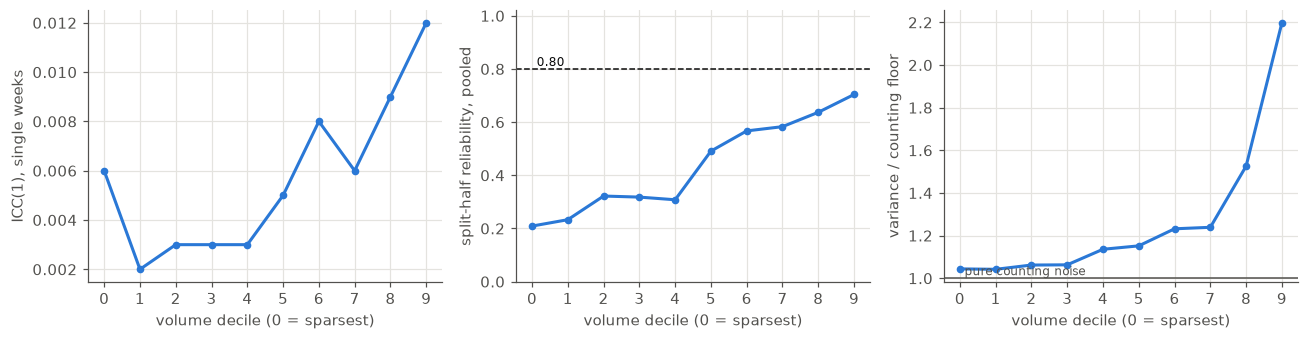

In [8]:
def plot_step0(step0):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
    x = step0["decile"].to_numpy()

    axes[0].plot(x, step0["ICC(1) mean"].to_numpy(), color=MAIN_COLOR, marker="o", markersize=4)
    axes[0].set_ylabel("ICC(1), single weeks")

    axes[1].plot(x, step0["split-half"].to_numpy(), color=MAIN_COLOR, marker="o", markersize=4)
    axes[1].axhline(PREDICTION_STRENGTH_THRESHOLD, color=TEXT_COLOR, linestyle="--", linewidth=1)
    axes[1].text(0.02, PREDICTION_STRENGTH_THRESHOLD, " 0.80", va="bottom",
                 color=TEXT_COLOR, fontsize=8)
    axes[1].set_ylim(0, 1.02)
    axes[1].set_ylabel("split-half reliability, pooled")

    axes[2].plot(x, step0["noise ratio"].to_numpy(), color=MAIN_COLOR, marker="o", markersize=4)
    axes[2].axhline(1.0, color=MUTED_TEXT_COLOR, linewidth=1)
    axes[2].text(0.02, 1.0, " pure counting noise", va="bottom",
                 color=MUTED_TEXT_COLOR, fontsize=8)
    axes[2].set_ylabel("variance / counting floor")

    for ax in axes:
        ax.set_xlabel("volume decile (0 = sparsest)")
        ax.set_xticks(range(10))
    fig.tight_layout()
    return fig

plot_step0(step0)
plt.show()

## 3. Step 1 — could the pipeline find structure if there were any?

Without this number a negative result is uninterpretable, because "it is a continuum"
and "we were underpowered" look identical from the outside.

Four archetypes are planted **at this sample size, these weekly totals, this counting
noise**, riding on the real population's own mean profile so that its envelope and
quirks are present rather than assumed away. Each series scatters around its archetype —
the continuum component, which keeps the control from being trivially easy — and its
weeks are redrawn as multinomial counts at its real totals.

The knob is arbitrary, so what gets reported is the separation actually achieved:
$\delta$ = smallest gap between centroids over the pooled cloud radius.

In [9]:
base_profile = Xr.mean(axis=0)
control = []
for sep in SEP_GRID:
    simulation = positive_control(base_profile, totals_r, n_clusters=4, sep=sep, seed=SEED)
    estimate, strengths = k_hat(simulation.shapes, max_k=MAX_K, n_draws=N_DRAWS, seed=SEED)
    finite = [value for value in strengths.values() if np.isfinite(value)]
    labels = _fit_gmm(simulation.shapes, 4, seed=SEED).predict(simulation.shapes)
    control.append({"sep": sep, "delta": simulation.separation, "K_hat": estimate,
                    "ARI at K=4": adjusted_rand_score(simulation.labels, labels),
                    "max prediction strength": max(finite) if finite else float("nan"),
                    "shapes": simulation.shapes, "labels": simulation.labels})

detected = [row for row in control
            if row["K_hat"] == 4 and row["ARI at K=4"] >= ARI_THRESHOLD]
DETECTION_FLOOR = min(row["delta"] for row in detected) if detected else float("inf")
print(f"detection floor: delta >= {DETECTION_FLOOR:.2f}")
print("below it, absence of clusters is not evidence of absence")
pl.DataFrame([{k: v for k, v in row.items() if k not in ("shapes", "labels")}
              for row in control]).with_columns(
    [pl.col(name).round(2) for name in ["sep", "delta", "ARI at K=4", "max prediction strength"]])

detection floor: delta >= 1.50
below it, absence of clusters is not evidence of absence


sep,delta,K_hat,ARI at K=4,max prediction strength
f64,f64,i64,f64,f64
0.0,0.07,1,-0.0,0.53
0.15,0.52,1,0.27,0.63
0.25,0.96,1,0.51,0.74
0.4,1.5,4,0.93,0.98
0.6,1.94,4,0.99,1.0
0.9,2.24,4,1.0,1.0


/Users/amelien/Desktop/ML/BLOG/m5-chronos2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/amelien/Desktop/ML/BLOG/m5-chronos2/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/amelien/Desktop/ML/BLOG/m5-chronos2/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/amelien/Desktop/ML/BLOG/m5-chronos2/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


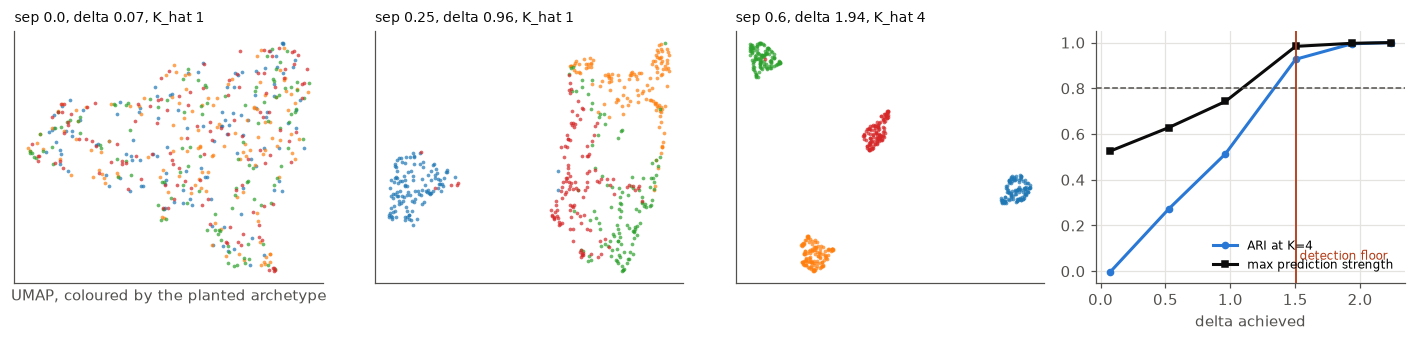

In [10]:
def plot_control(control, detection_floor):
    shown = [row for row in control if row["sep"] in (0.0, 0.25, 0.6)]
    fig, axes = plt.subplots(1, len(shown) + 1, figsize=(13, 3.2))

    for ax, row in zip(axes, shown):
        coordinates, method = umap_layout(row["shapes"], seed=LAYOUT_SEED)
        for cluster in np.unique(row["labels"]):
            members = row["labels"] == cluster
            ax.scatter(coordinates[members, 0], coordinates[members, 1], s=6, alpha=0.7,
                       linewidths=0)
        ax.set_title(f"sep {row['sep']}, delta {row['delta']:.2f}, "
                     f"K_hat {row['K_hat']}", loc="left", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    axes[0].set_xlabel(f"{method}, coloured by the planted archetype")

    ax = axes[-1]
    deltas = [row["delta"] for row in control]
    ax.plot(deltas, [row["ARI at K=4"] for row in control], color=MAIN_COLOR,
            marker="o", markersize=4, label="ARI at K=4")
    ax.plot(deltas, [row["max prediction strength"] for row in control], color=TEXT_COLOR,
            marker="s", markersize=4, label="max prediction strength")
    ax.axhline(ARI_THRESHOLD, color=MUTED_TEXT_COLOR, linestyle="--", linewidth=1)
    if np.isfinite(detection_floor):
        ax.axvline(detection_floor, color="#b23c17", linewidth=1.2)
        ax.text(detection_floor, 0.05, " detection floor", color="#b23c17", fontsize=8)
    ax.set_xlabel("delta achieved")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    return fig

plot_control(control, DETECTION_FLOOR)
plt.show()

## 4. Step 2 — does the pipeline invent structure when there is none?

A specificity test is only as good as the fake data it runs on, and this is where most
clustering analyses quietly fail. A hand-written family of curves is useless as evidence
about a real population, because nothing about its geometry came from the data.

The null used here is **fitted to the real cloud**: the dominant axis of variation by
SVD, a smooth manifold estimated along it as a local mean over nearest neighbours, and
Gaussian residuals carrying the real residual covariance, with weeks redrawn at the real
weekly totals. It is the real cloud with multimodality removed *by construction* —
Gaussian residuals about a smooth manifold cannot be multimodal — keeping the spread, the
dimensions and the counting noise.

**The resemblance is shown, not asserted.** If the null is more diffuse than the real
cloud it clusters less reproducibly, the real data beats it too easily, and the p-value is
biased toward finding structure. That is the dangerous direction, so it is the one checked.

In [11]:
reference_null = fitted_null(Xr, totals_r, seed=SEED)
geometry = geometry_comparison(Xr, reference_null.shapes)
print(f"worst per-coordinate spread ratio {geometry['worst_spread_ratio']:.2f}  "
      f"(1.00 = identical)")
print(f"median pairwise distance ratio    {geometry['pairwise_ratio']:.2f}")
print(f"median nearest-neighbour ratio    {geometry['nearest_ratio']:.2f}")
if geometry["worst_spread_ratio"] > 1.5:
    print("\nWARNING: the null does not match the real cloud's geometry. "
          "The p-value below is not readable.")

worst per-coordinate spread ratio 3.90  (1.00 = identical)
median pairwise distance ratio    1.80
median nearest-neighbour ratio    1.72



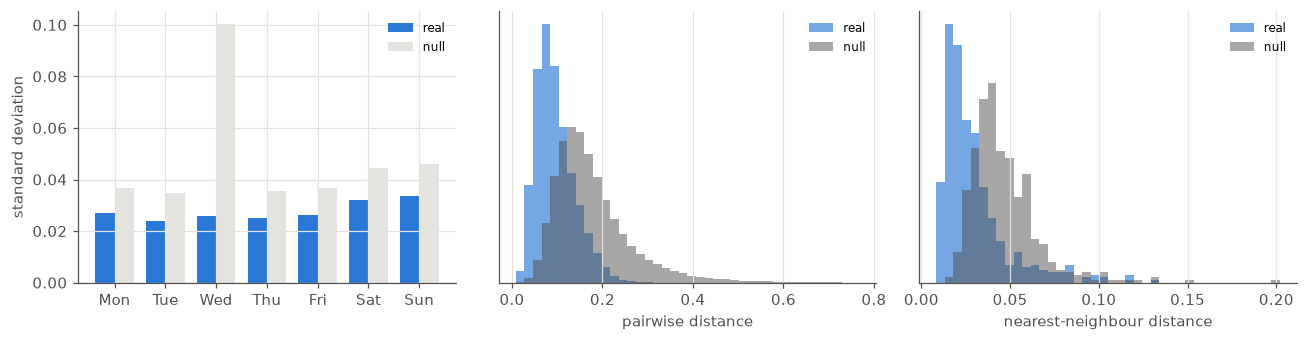

In [12]:
def plot_geometry(geometry):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
    width = 0.38
    positions = np.arange(WEEKDAYS)
    axes[0].bar(positions - width / 2, geometry["spread_real"], width, color=MAIN_COLOR, label="real")
    axes[0].bar(positions + width / 2, geometry["spread_null"], width, color=GRID_COLOR, label="null")
    axes[0].set_xticks(positions); axes[0].set_xticklabels(DAY_NAMES)
    axes[0].set_ylabel("standard deviation"); axes[0].legend(fontsize=8)

    for ax, key, label in [(axes[1], "pairwise", "pairwise distance"),
                           (axes[2], "nearest", "nearest-neighbour distance")]:
        bins = np.histogram_bin_edges(np.concatenate([geometry[f"{key}_real"],
                                                      geometry[f"{key}_null"]]), bins=40)
        ax.hist(geometry[f"{key}_real"], bins=bins, color=MAIN_COLOR, alpha=0.65,
                density=True, label="real")
        ax.hist(geometry[f"{key}_null"], bins=bins, color=MUTED_TEXT_COLOR, alpha=0.5,
                density=True, label="null")
        ax.set_xlabel(label); ax.set_yticks([]); ax.legend(fontsize=8)
    fig.tight_layout()
    return fig

plot_geometry(geometry)
plt.show()

In [13]:
envelope_path = ARTIFACTS_DIR / "experiments" / f"shape_null_envelope_{NAME}.json"


def restore(record):
    # JSON has no integer keys and no arrays; put both back so the rest of the notebook
    # cannot tell a cached envelope from a freshly computed one.
    record["real_strengths"] = {int(k): v for k, v in record["real_strengths"].items()}
    record["null_curves"] = [{int(k): v for k, v in curve.items()}
                             for curve in record["null_curves"]]
    record["null_maxima"] = np.array(record["null_maxima"])
    record["null_k_hat"] = np.array(record["null_k_hat"])
    return record


if envelope_path.exists() and not FORCE_RECOMPUTE:
    envelope = restore(json.loads(envelope_path.read_text()))
    print(f"read back from {envelope_path.name}")
else:
    envelope = null_envelope(Xr, totals_r, n_nulls=N_NULLS, max_k=MAX_K,
                             n_draws=max(N_DRAWS // 2, 4), seed=SEED)
    envelope_path.parent.mkdir(parents=True, exist_ok=True)
    envelope_path.write_text(json.dumps(envelope, indent=2, default=lambda v: v.tolist()))
    print(f"computed and saved to {envelope_path.name}")

print(f"real K_hat = {envelope['real_k_hat']}")
print(f"max prediction strength: real {envelope['real_max']:.3f}, "
      f"null median {np.median(envelope['null_maxima']):.3f}")
print(f"p = {envelope['p_value']:.3f}  (floor {envelope['min_p_value']:.3f} with "
      f"{envelope['n_nulls']} nulls; beat every null: {envelope['beat_all_nulls']})")
print(f"K_hat on the nulls: {np.bincount(envelope['null_k_hat'], minlength=MAX_K + 1).tolist()}")

read back from shape_null_envelope_n500_seed42.json
real K_hat = 1
max prediction strength: real 0.746, null median 0.607
p = 0.024  (floor 0.024 with 40 nulls; beat every null: True)
K_hat on the nulls: [0, 40, 0, 0, 0, 0, 0]


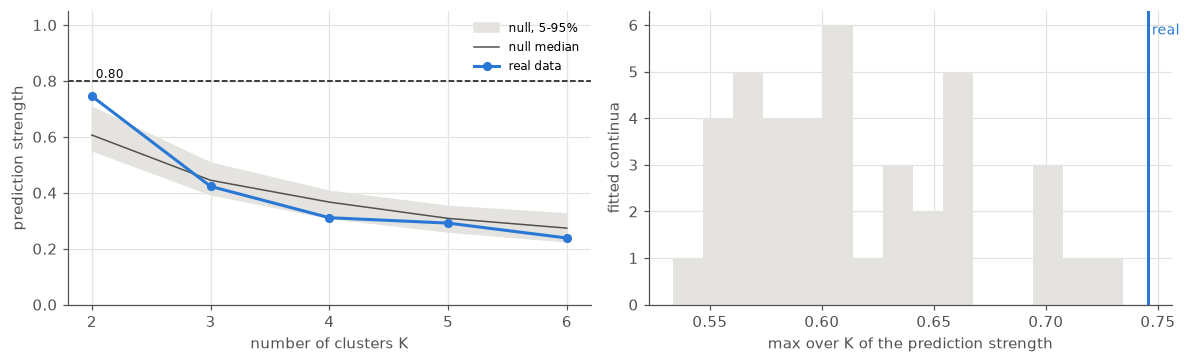

In [14]:
def plot_envelope(envelope):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

    ax = axes[0]
    ks = sorted(envelope["real_strengths"])
    real = [envelope["real_strengths"][k] for k in ks]
    null = np.array([[curve.get(k, np.nan) for k in ks] for curve in envelope["null_curves"]])
    low = np.nanpercentile(null, 5, axis=0)
    high = np.nanpercentile(null, 95, axis=0)
    ax.fill_between(ks, low, high, color=GRID_COLOR, label="null, 5-95%")
    ax.plot(ks, np.nanmedian(null, axis=0), color=MUTED_TEXT_COLOR, linewidth=1, label="null median")
    ax.plot(ks, real, color=MAIN_COLOR, marker="o", markersize=5, label="real data")
    ax.axhline(PREDICTION_STRENGTH_THRESHOLD, color=TEXT_COLOR, linestyle="--", linewidth=1)
    ax.text(ks[0], PREDICTION_STRENGTH_THRESHOLD, " 0.80", va="bottom", color=TEXT_COLOR, fontsize=8)
    ax.set_xlabel("number of clusters K"); ax.set_ylabel("prediction strength")
    ax.set_xticks(ks); ax.set_ylim(0, 1.05); ax.legend(fontsize=8)

    ax = axes[1]
    ax.hist(envelope["null_maxima"], bins=15, color=GRID_COLOR)
    ax.axvline(envelope["real_max"], color=MAIN_COLOR, linewidth=2)
    ax.text(envelope["real_max"], ax.get_ylim()[1] * 0.92, " real ", ha="left",
            color=MAIN_COLOR, fontsize=9)
    ax.set_xlabel("max over K of the prediction strength")
    ax.set_ylabel("fitted continua")
    fig.tight_layout()
    return fig

plot_envelope(envelope)
plt.show()

## 5. Step 4 — is the distance measuring shape, or where the week sits?

Euclidean distance on a 7-vector is not shift-invariant: two series with the same shape
one day apart land far apart. That may be exactly right — Saturday is Saturday, and the
forecast is made in calendar days — but it raises a fair objection. If a one-day offset
is larger than the typical between-series difference, the clustering is sorting series by
*where their week sits* rather than by shape.

**A week has only 7 rotations, so $\tau^* = 0$ happens 14% of the time by luck alone.**
With only 7 positions the raw share cannot be read directly against a chance level the
way it could on a finer grid. So the test is also run on a copy of the same
cloud with every series randomly rotated — same geometry, alignment destroyed — and the
comparison between the two is the result.

In [15]:
alignment = shift_test(Xr, seed=SEED)
print(f"tau* = 0 for {100 * alignment['share_aligned']:.1f}% of pairs "
      f"({100 * alignment['share_within_one']:.1f}% within +-1 day)")
print(f"  randomly rotated reference: {100 * alignment['share_aligned_reference']:.1f}%, "
      f"chance level {100 * alignment['chance_level']:.1f}%")
print(f"  alignment lift x{alignment['alignment_lift']:.2f}")
print(f"median share of squared distance a rotation removes: {alignment['median_gain']:.3f}"
      f"  (reference {alignment['median_gain_reference']:.3f})")

tau* = 0 for 36.8% of pairs (78.6% within +-1 day)
  randomly rotated reference: 14.3%, chance level 14.3%
  alignment lift x2.58
median share of squared distance a rotation removes: 0.209  (reference 0.566)


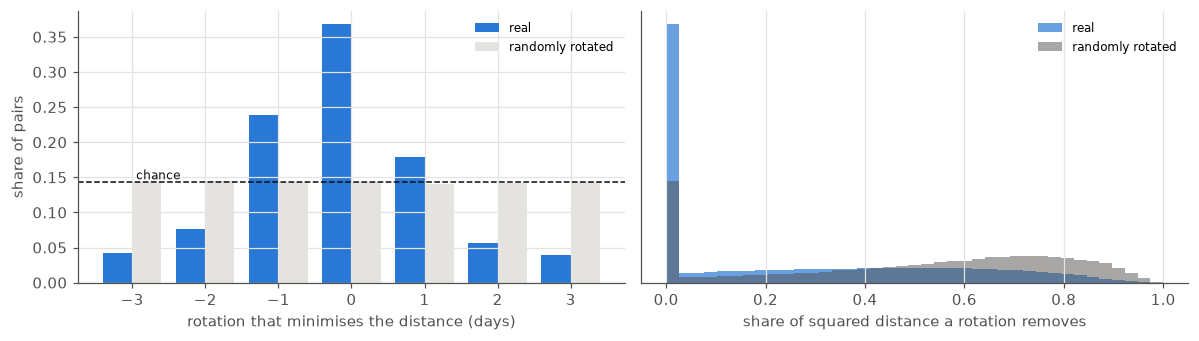

In [16]:
def plot_alignment(alignment):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    shifts = np.arange(-(WEEKDAYS // 2), WEEKDAYS // 2 + 1)

    ax = axes[0]
    width = 0.4
    for offset, (key, color, label) in enumerate([
            ("shift", MAIN_COLOR, "real"), (None, GRID_COLOR, "randomly rotated")]):
        values = alignment["shift"] if key else alignment["reference"]["shift"]
        counts = np.array([np.mean(values == s) for s in shifts])
        ax.bar(shifts + (offset - 0.5) * width, counts, width, color=color, label=label)
    ax.axhline(alignment["chance_level"], color=TEXT_COLOR, linestyle="--", linewidth=1)
    ax.text(shifts[0], alignment["chance_level"], " chance", va="bottom",
            color=TEXT_COLOR, fontsize=8)
    ax.set_xlabel("rotation that minimises the distance (days)")
    ax.set_ylabel("share of pairs"); ax.set_xticks(shifts); ax.legend(fontsize=8)

    ax = axes[1]
    bins = np.linspace(0, 1, 40)
    ax.hist(alignment["gain"], bins=bins, color=MAIN_COLOR, alpha=0.7, density=True, label="real")
    ax.hist(alignment["reference"]["gain"], bins=bins, color=MUTED_TEXT_COLOR, alpha=0.5,
            density=True, label="randomly rotated")
    ax.set_xlabel("share of squared distance a rotation removes")
    ax.set_yticks([]); ax.legend(fontsize=8)
    fig.tight_layout()
    return fig

plot_alignment(alignment)
plt.show()

## 6. The verdict, and what it does to notebook 09's question

The rule was fixed in the opening cell: discrete types are claimed only if prediction
strength clears 0.80 at some $K \geq 2$, that result beats the fitted null at $p < 0.05$,
and the separation exceeds the detection floor of step 1.

In [17]:
cleared_threshold = envelope["real_k_hat"] >= 2
beat_null = envelope["p_value"] < 0.05
geometry_ok = geometry["worst_spread_ratio"] <= 1.5

if envelope["real_k_hat"] >= 2:
    labels = _fit_gmm(Xr, envelope["real_k_hat"], seed=SEED).predict(Xr)
    achieved = separation(Xr, labels)
else:
    labels, achieved = np.zeros(len(Xr), dtype=int), 0.0
above_floor = achieved >= DETECTION_FLOOR

print(f"prediction strength clears 0.80 at K >= 2 : {cleared_threshold} (K_hat={envelope['real_k_hat']})")
print(f"beats the fitted continuum at p < 0.05    : {beat_null} (p={envelope['p_value']:.3f})")
print(f"separation above the detection floor      : {above_floor} "
      f"(delta={achieved:.2f} vs floor {DETECTION_FLOOR:.2f})")
print(f"null geometry trustworthy                 : {geometry_ok}")
print()

if cleared_threshold and beat_null and above_floor and geometry_ok:
    VERDICT = (f"Discrete types: {envelope['real_k_hat']} reproducible clusters, above the "
               "detection floor and beyond what a fitted continuum produces.")
elif not geometry_ok:
    VERDICT = ("Inconclusive: the fitted null does not reproduce the real cloud's geometry, "
               "so its p-value cannot be read.")
elif DETECTION_FLOOR == float("inf"):
    VERDICT = ("Underpowered: the pipeline could not recover planted archetypes at any "
               "separation tried, so absence of clusters here is not evidence of absence.")
else:
    VERDICT = ("One continuum. The population has no reproducible discrete types above a "
               f"separation of {DETECTION_FLOOR:.2f}, which the positive control shows "
               "would have been detected.")
print(VERDICT)

prediction strength clears 0.80 at K >= 2 : False (K_hat=1)
beats the fitted continuum at p < 0.05    : True (p=0.024)
separation above the detection floor      : False (delta=0.00 vs floor 1.50)
null geometry trustworthy                 : False

Inconclusive: the fitted null does not reproduce the real cloud's geometry, so its p-value cannot be read.


/Users/amelien/Desktop/ML/BLOG/m5-chronos2/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


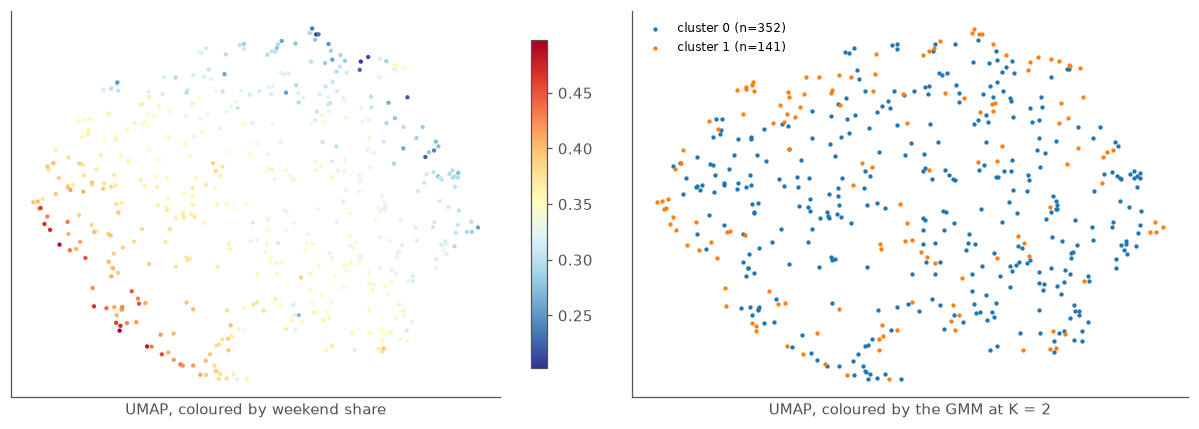

In [18]:
def plot_population(Xr, labels, envelope):
    coordinates, method = umap_layout(Xr, seed=LAYOUT_SEED)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4),
                             gridspec_kw={"width_ratios": [1.1, 1]})

    ax = axes[0]
    weekend = Xr[:, 5] + Xr[:, 6]
    points = ax.scatter(coordinates[:, 0], coordinates[:, 1], c=weekend, cmap="RdYlBu_r",
                        s=8, linewidths=0)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_xlabel(f"{method}, coloured by weekend share")
    fig.colorbar(points, ax=ax, shrink=0.85)

    ax = axes[1]
    for cluster in np.unique(labels):
        members = labels == cluster
        ax.scatter(coordinates[members, 0], coordinates[members, 1], s=8, linewidths=0,
                   label=f"cluster {cluster} (n={members.sum()})")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_xlabel(f"{method}, coloured by the GMM at K = {max(envelope['real_k_hat'], 2)}")
    ax.legend(fontsize=8, loc="best")
    fig.tight_layout()
    return fig

display_labels = labels if envelope["real_k_hat"] >= 2 else _fit_gmm(Xr, 2, seed=SEED).predict(Xr)
plot_population(Xr, display_labels, envelope)
plt.show()

In [19]:
record = {
    "n_series_total": int(len(X)),
    "n_series_audited": int(len(Xr)),
    "min_weeks": MIN_WEEKS,
    "reliable_decile_floor": FLOOR_DECILE,
    "split_half_audited": round(split_half_reliability(blocks_r, n_draws=12, seed=SEED), 4),
    "detection_floor_delta": None if DETECTION_FLOOR == float("inf") else round(DETECTION_FLOOR, 3),
    "k_hat": int(envelope["real_k_hat"]),
    "prediction_strength": {str(k): round(float(v), 4)
                            for k, v in envelope["real_strengths"].items()},
    "p_value": round(envelope["p_value"], 4),
    "p_value_floor": round(envelope["min_p_value"], 4),
    "n_nulls": envelope["n_nulls"],
    "null_geometry_worst_spread_ratio": round(geometry["worst_spread_ratio"], 3),
    "separation_achieved": round(float(achieved), 3),
    "alignment": {
        "share_tau_zero": round(alignment["share_aligned"], 4),
        "share_tau_zero_reference": round(alignment["share_aligned_reference"], 4),
        "lift": round(alignment["alignment_lift"], 3),
        "median_gain": round(alignment["median_gain"], 4),
    },
    "verdict": VERDICT,
}
path = ARTIFACTS_DIR / f"shape_structure_{NAME}.json"
path.write_text(json.dumps(record, indent=2))
print(f"Saved to {path.name}")
VERDICT

Saved to shape_structure_n500_seed42.json


"Inconclusive: the fitted null does not reproduce the real cloud's geometry, so its p-value cannot be read."

**What this does to notebook 09's question.** Those two results have to be read together,
because neither settles the grouping question alone.

Notebook 09 found a large, durable item effect: the hard items stay hard. This notebook
asks whether the items differ in *kind* or only in *degree*. A continuum here does not
contradict 09 — it says the stable differences are continuous, that any cut through them
is arbitrary wherever it is placed, and that the instrument the data licenses is a
continuous covariate rather than a partition. And since the strongest continuous
candidate, volume, is something Chronos-2 reads off the history unaided, that is close to
saying the model already has it. Discrete types, on the other hand, would make per-type
fine-tuning a concrete next experiment rather than a hope.

**How much to trust this.** Three limits.

1. **Shape is not the only thing a type could differ in.** This audit clusters the weekly
   profile because that is the construction this study is built on. Two items with the same
   weekly shape but different burstiness, promotion response or lifecycle would count as
   one population here. A negative result is about *this* object, not about every possible
   grouping.
2. **Three steps of the full audit are not run.** The dimension sweep is nearly vacuous at
   7 dimensions, where a full-covariance GMM has 35 parameters per component; it earns its
   place only on much wider profiles, where that count explodes. The drift decomposition (does the shape itself move
   over time?) and the forward-scored window length are real omissions, and the first of
   them would matter if a later notebook tried to act on the clusters.
3. **The reliability filter changes the population.** The audit runs on the volume deciles
   whose profile clears 0.80, which are not a random sample of the roster — they are the
   items most likely to be groupable. That biases toward finding structure, so a continuum
   verdict survives it.

## Notes

*Your observations here.*